In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

# pandas settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

In [5]:
# site = "local" # if you are running the code on your local machine, update path accordingly
site = "farm" # if you are running the code on farm, update path accordingly

dataset_name = "merfish_mouse_brain_239-batch"
relevant_keys = ['cell_type', 'major_brain_region', 'ccf_region_name']
if site == "local":
    raw_stats_directory = Path("/Users/am84/Desktop/Research/Mo-Lotfollahi/TERRA/results/silver_statistics/")
    plots_directory = Path("/Users/am84/Desktop/Research/Mo-Lotfollahi/TERRA/plots/silver_statistics") / dataset_name
elif site == "farm":
    raw_stats_directory = Path("/lustre/scratch126/cellgen/team361/am84/TERRA/results/silver_statistics/")
    plots_directory = Path("/lustre/scratch126/cellgen/team361/am84/TERRA/plots/silver_statistics/") / dataset_name

os.makedirs(plots_directory, exist_ok=True)
    
stats_fname = raw_stats_directory / dataset_name / f"{dataset_name}_statistics.csv"

# Create Dataframes

In [12]:
def create_dataframe(fname, relevant_keys):
    df = pd.read_csv(fname)
    df = df.sort_values(by=['n_cells'])
    relevant_key_columns = {}
    columns = ['batch_id', 'n_cells', 'n_genes']
    for key in relevant_keys:
        relevant_key_columns[key] = [col for col in df.columns if col.startswith(key)]
        columns += relevant_key_columns[key]
    df = df[columns]
    return df, relevant_key_columns

In [13]:
df, relevant_key_columns = create_dataframe(stats_fname, relevant_keys)
print(f"Dataset: {dataset_name}")
display(df)

Dataset: merfish_mouse_brain_239-batch


,batch_id,n_cells,n_genes,cell_type_glutamatergic neuron,cell_type_endothelial cell,cell_type_astrocyte,cell_type_GABAergic neuron,cell_type_oligodendrocyte,cell_type_microglial cell,cell_type_oligodendrocyte precursor cell,cell_type_pericyte,cell_type_vascular leptomeningeal cell,cell_type_smooth muscle cell,cell_type_macrophage,cell_type_neuroblast (sensu Vertebrata),cell_type_lymphocyte,cell_type_dendritic cell,cell_type_dopaminergic neuron,cell_type_tanycyte,cell_type_olfactory ensheathing cell,cell_type_glycinergic neuron,cell_type_Bergmann glial cell,cell_type_monocyte,cell_type_ependymal cell,cell_type_choroid plexus epithelial cell,cell_type_histaminergic neuron,cell_type_hypendymal cell,cell_type_cholinergic neuron,major_brain_region_Isocortex,major_brain_region_Olfactory,major_brain_region_nan,major_brain_region_Fiber_tracts,major_brain_region_Thalamus,major_brain_region_Hypothalamus,major_brain_region_Hippocampus,major_brain_region_Striatum,major_brain_region_Cortical_subplate,major_brain_region_Ventricular_systems,major_brain_region_Pallidum,major_brain_region_Cerebellum,major_brain_region_Midbrain,major_brain_region_Medulla,major_brain_region_Pons,major_brain_region_n/a,ccf_region_name_Anterior olfactory nucleus,"ccf_region_name_Secondary motor area, layer 5","ccf_region_name_Secondary motor area, layer 2/3",ccf_region_name_nan,"ccf_region_name_Orbital area, lateral part, layer 5","ccf_region_name_Orbital area, ventrolateral part, layer 5","ccf_region_name_Prelimbic area, layer 5",ccf_region_name_Olfactory areas,"ccf_region_name_Orbital area, medial part, layer 5","ccf_region_name_Orbital area, ventrolateral part, layer 2/3","ccf_region_name_Orbital area, medial part, layer 2/3","ccf_region_name_Orbital area, medial part, layer 1","ccf_region_name_Agranular insular area, dorsal part, layer 5","ccf_region_name_Secondary motor area, layer 1","ccf_region_name_Prelimbic area, layer 1","ccf_region_name_Taenia tecta, ventral part","ccf_region_name_Orbital area, lateral part, layer 2/3","ccf_region_name_Agranular insular area, dorsal part, layer 2/3","ccf_region_name_anterior commissure, olfactory limb","ccf_region_name_Taenia tecta, dorsal part","ccf_region_name_Orbital area, lateral part, layer 6a","ccf_region_name_Prelimbic area, layer 2/3","ccf_region_name_Frontal pole, layer 6a","ccf_region_name_lateral olfactory tract, body","ccf_region_name_Secondary motor area, layer 6a","ccf_region_name_Orbital area, lateral part, layer 1","ccf_region_name_Orbital area, ventrolateral part, layer 1","ccf_region_name_Orbital area, ventrolateral part, layer 6a","ccf_region_name_Primary motor area, Layer 2/3","ccf_region_name_Prelimbic area, layer 6a","ccf_region_name_Agranular insular area, ventral part, layer 2/3","ccf_region_name_Anterior cingulate area, dorsal part, layer 1","ccf_region_name_Primary motor area, Layer 1","ccf_region_name_Agranular insular area, dorsal part, layer 1","ccf_region_name_Anterior cingulate area, dorsal part, layer 2/3","ccf_region_name_Anterior cingulate area, dorsal part, layer 5","ccf_region_name_Orbital area, medial part, layer 6a","ccf_region_name_Agranular insular area, ventral part, layer 1","ccf_region_name_Agranular insular area, dorsal part, layer 6a","ccf_region_name_Agranular insular area, ventral part, layer 5",ccf_region_name_Field CA1,ccf_region_name_Medial amygdalar nucleus,ccf_region_name_Caudoputamen,ccf_region_name_Piriform area,"ccf_region_name_corpus callosum, splenium",ccf_region_name_Ventral posteromedial nucleus of the thalamus,ccf_region_name_Medial habenula,"ccf_region_name_Dentate gyrus, granule cell layer",ccf_region_name_Dorsomedial nucleus of the hypothalamus,ccf_region_name_Lateral amygdalar nucleus,ccf_region_name_fiber tracts,ccf_region_name_Hypothalamus,"ccf_region_name_Retrosplenial area, ventral part, layer 2/3",ccf_region_name_optic radiation,ccf_region_name_Field CA3,ccf_region_name_Lateral hypothalamic area,ccf_region_name_lateral ventricle,"ccf_region_name_Dentat

In [14]:
relevant_key_columns['major_brain_region']

['major_brain_region_Isocortex',
 'major_brain_region_Olfactory',
 'major_brain_region_nan',
 'major_brain_region_Fiber_tracts',
 'major_brain_region_Thalamus',
 'major_brain_region_Hypothalamus',
 'major_brain_region_Hippocampus',
 'major_brain_region_Striatum',
 'major_brain_region_Cortical_subplate',
 'major_brain_region_Ventricular_systems',
 'major_brain_region_Pallidum',
 'major_brain_region_Cerebellum',
 'major_brain_region_Midbrain',
 'major_brain_region_Medulla',
 'major_brain_region_Pons',
 'major_brain_region_n/a']

In [16]:
display(df[(df['major_brain_region_nan'] == 0) & (df['major_brain_region_n/a'] == 0)])


,batch_id,n_cells,n_genes,cell_type_glutamatergic neuron,cell_type_endothelial cell,cell_type_astrocyte,cell_type_GABAergic neuron,cell_type_oligodendrocyte,cell_type_microglial cell,cell_type_oligodendrocyte precursor cell,cell_type_pericyte,cell_type_vascular leptomeningeal cell,cell_type_smooth muscle cell,cell_type_macrophage,cell_type_neuroblast (sensu Vertebrata),cell_type_lymphocyte,cell_type_dendritic cell,cell_type_dopaminergic neuron,cell_type_tanycyte,cell_type_olfactory ensheathing cell,cell_type_glycinergic neuron,cell_type_Bergmann glial cell,cell_type_monocyte,cell_type_ependymal cell,cell_type_choroid plexus epithelial cell,cell_type_histaminergic neuron,cell_type_hypendymal cell,cell_type_cholinergic neuron,major_brain_region_Isocortex,major_brain_region_Olfactory,major_brain_region_nan,major_brain_region_Fiber_tracts,major_brain_region_Thalamus,major_brain_region_Hypothalamus,major_brain_region_Hippocampus,major_brain_region_Striatum,major_brain_region_Cortical_subplate,major_brain_region_Ventricular_systems,major_brain_region_Pallidum,major_brain_region_Cerebellum,major_brain_region_Midbrain,major_brain_region_Medulla,major_brain_region_Pons,major_brain_region_n/a,ccf_region_name_Anterior olfactory nucleus,"ccf_region_name_Secondary motor area, layer 5","ccf_region_name_Secondary motor area, layer 2/3",ccf_region_name_nan,"ccf_region_name_Orbital area, lateral part, layer 5","ccf_region_name_Orbital area, ventrolateral part, layer 5","ccf_region_name_Prelimbic area, layer 5",ccf_region_name_Olfactory areas,"ccf_region_name_Orbital area, medial part, layer 5","ccf_region_name_Orbital area, ventrolateral part, layer 2/3","ccf_region_name_Orbital area, medial part, layer 2/3","ccf_region_name_Orbital area, medial part, layer 1","ccf_region_name_Agranular insular area, dorsal part, layer 5","ccf_region_name_Secondary motor area, layer 1","ccf_region_name_Prelimbic area, layer 1","ccf_region_name_Taenia tecta, ventral part","ccf_region_name_Orbital area, lateral part, layer 2/3","ccf_region_name_Agranular insular area, dorsal part, layer 2/3","ccf_region_name_anterior commissure, olfactory limb","ccf_region_name_Taenia tecta, dorsal part","ccf_region_name_Orbital area, lateral part, layer 6a","ccf_region_name_Prelimbic area, layer 2/3","ccf_region_name_Frontal pole, layer 6a","ccf_region_name_lateral olfactory tract, body","ccf_region_name_Secondary motor area, layer 6a","ccf_region_name_Orbital area, lateral part, layer 1","ccf_region_name_Orbital area, ventrolateral part, layer 1","ccf_region_name_Orbital area, ventrolateral part, layer 6a","ccf_region_name_Primary motor area, Layer 2/3","ccf_region_name_Prelimbic area, layer 6a","ccf_region_name_Agranular insular area, ventral part, layer 2/3","ccf_region_name_Anterior cingulate area, dorsal part, layer 1","ccf_region_name_Primary motor area, Layer 1","ccf_region_name_Agranular insular area, dorsal part, layer 1","ccf_region_name_Anterior cingulate area, dorsal part, layer 2/3","ccf_region_name_Anterior cingulate area, dorsal part, layer 5","ccf_region_name_Orbital area, medial part, layer 6a","ccf_region_name_Agranular insular area, ventral part, layer 1","ccf_region_name_Agranular insular area, dorsal part, layer 6a","ccf_region_name_Agranular insular area, ventral part, layer 5",ccf_region_name_Field CA1,ccf_region_name_Medial amygdalar nucleus,ccf_region_name_Caudoputamen,ccf_region_name_Piriform area,"ccf_region_name_corpus callosum, splenium",ccf_region_name_Ventral posteromedial nucleus of the thalamus,ccf_region_name_Medial habenula,"ccf_region_name_Dentate gyrus, granule cell layer",ccf_region_name_Dorsomedial nucleus of the hypothalamus,ccf_region_name_Lateral amygdalar nucleus,ccf_region_name_fiber tracts,ccf_region_name_Hypothalamus,"ccf_region_name_Retrosplenial area, ventral part, layer 2/3",ccf_region_name_optic radiation,ccf_region_name_Field CA3,ccf_region_name_Lateral hypothalamic area,ccf_region_name_lateral ventricle,"ccf_region_name_Dentat

In [154]:
def subset_dataframe(df, 
                     subset_by_n_cells=True,
                     n_cells_threshold=100000): 
    if subset_by_n_cells:
        # find rows with n_cells > n_cells_threshold
        subset_df = df[df['n_cells'] >= n_cells_threshold]
        batch_ids = subset_df['batch_id'].tolist()
    else:
        subset_df = df
        batch_ids = subset_df['batch_id'].tolist()
    return batch_ids, subset_df

In [177]:
n_cells_threshold = 100000
hundredk_batch_ids, hundredk_subset_df = subset_dataframe(df, 
                                                            subset_by_n_cells=True, 
                                                            n_cells_threshold=n_cells_threshold)
display(hundredk_subset_df)

,batch_id,n_cells,n_genes,cell_glutamatergic neuron,cell_endothelial cell,cell_astrocyte,cell_GABAergic neuron,cell_oligodendrocyte,cell_microglial cell,cell_oligodendrocyte precursor cell,cell_pericyte,cell_vascular leptomeningeal cell,cell_smooth muscle cell,cell_macrophage,cell_neuroblast (sensu Vertebrata),cell_lymphocyte,cell_dendritic cell,cell_dopaminergic neuron,cell_tanycyte,cell_olfactory ensheathing cell,cell_glycinergic neuron,cell_Bergmann glial cell,cell_monocyte,cell_ependymal cell,cell_choroid plexus epithelial cell,cell_histaminergic neuron,cell_hypendymal cell,cell_cholinergic neuron,niche_neocortex,niche_brain,niche_white matter,niche_thalamic complex,niche_hypothalamus,niche_hippocampal formation,niche_striatum,niche_cortical subplate,niche_ventricular system of brain,niche_pallidum,niche_hindbrain,niche_cerebellum,niche_midbrain
99,224,105954,1122,40187,8982,10153,14918,15889,3195,2413,1999,3400,1200,481,297.0,66,42,9.0,4.0,3.0,1191.0,964.0,3.0,232.0,324.0,0.0,1.0,1.0,21595.0,7529,15264.0,4728.0,637.0,9004.0,13826.0,1232.0,799.0,2474.0,6777.0,21393.0,696.0
74,214,107775,1122,38884,9311,12015,20052,11957,2688,2531,2000,1173,844,280,82.0,56,30,1083.0,15.0,2087.0,947.0,658.0,12.0,881.0,113.0,38.0,1.0,37.0,21762.0,14279,6588.0,8192.0,10138.0,1489.0,5819.0,0.0,1304.0,1276.0,7636.0,12324.0,16968.0
235,223,110927,1122,31108,10169,11754,21798,17450,3348,2554,2172,2436,889,377,594.0,55,31,1057.0,7.0,2277.0,1547.0,779.0,9.0,205.0,280.0,3.0,1.0,27.0,19294.0,20193,11246.0,5214.0,754.0,7051.0,13736.0,904.0,902.0,3382.0,11246.0,12143.0,4862.0
220,222,113720,1122,31466,10240,11905,24673,17230,3455,2521,2216,2175,1086,355,729.0,52,33,1072.0,2.0,1159.0,1977.0,703.0,4.0,231.0,319.0,0.0,1.0,116.0,19031.0,20977,12740.0,5362.0,1119.0,6359.0,11754.0,479.0,986.0,3767.0,11223.0,12426.0,7497.0
6,221,126309,1122,33290,11386,13165,29227,19749,3418,2697,2349,2921,1192,406,999.0,119,48,779.0,9.0,557.0,2324.0,761.0,5.0,304.0,427.0,0.0,0.0,177.0,18088.0,25447,14400.0,5439.0,2518.0,5211.0,10597.0,397.0,1114.0,3005.0,16159.0,12276.0,11658.0
112,219,127327,1122,38032,10325,12730,28427,19133,3000,2541,2144,2313,1017,348,2511.0,79,32,383.0,2.0,359.0,2004.0,1112.0,5.0,285.0,473.0,1.0,0.0,71.0,15992.0,23433,11908.0,4841.0,4372.0,3470.0,9448.0,0.0,1027.0,2704.0,16407.0,19538.0,14187.0
156,215,128295,1122,44374,11095,13316,25692,16402,3005,2818,2272,1602,1058,288,217.0,61,31,1539.0,9.0,617.0,1847.0,1049.0,8.0,592.0,225.0,16.0,0.0,162.0,22328.0,22139,9261.0,6070.0,8118.0,2605.0,6589.0,0.0,1532.0,1043.0,14766.0,16785.0,17059.0
180,220,137117,1122,37335,11519,13317,35335,20430,3414,2904,2440,2803,1073,441,1393.0,86,48,654.0,3.0,320.0,1777.0,909.0,8.0,322.0,514.0,1.0,0.0,71.0,20274.0,31161,12999.0,5523.0,3851.0,4600.0,10528.0,47.0,1051.0,2677.0,14465.0,16602.0,13339.0
204,216,146832,1122,50386,11970,14665,31665,19187,3448,3015,2625,1702,947,323,724.0,75,28,1475.0,6.0,431.0,1942.0,1425.0,7.0,532.0,192.0,30.0,1.0,31.0,23369.0,27826,10308.0,6427.0,7597.0,3355.0,7731.0,0.0,1133.0,1710.0,15767.0,23494.0,18115.0
83,217,155538,1122,46767,11322,16063,39435,19185,3193,2933,2346,2222,1097,402,3789.0,74,28,565.0,7.0,237.0,2624.0,1639.0,3.0,1257.0,257.0,63.0,4.0,26.0,19278.0,33928,10314.0,5766.0,5996.0,3435.0,9484.0,0.0,2777.0,2862.0,19304.0,24818.0,17576.0


# Create Histogram Plots

## Histogram of Number of Cells across AnnData Batches

In [170]:
def histogram_num_cells(df,
                        save_plot=True,
                        plots_directory=plots_directory,
                        dataset_name=dataset_name):
    
    fig,ax = plt.subplots(1,1,figsize=(6,4))

    sns.histplot(data=df, x='n_cells',ax=ax)

    ax.set_xlabel('Number of Samples (per batch)')
    ax.set_ylabel('Number of Batches')
    ax.set_title(f'Histogram of batchwise Number of Cells in {dataset_name} data')
    xticklabels = [f'{int(label)//1000}K' if label != '0' else label for label in ax.get_xticks()]
    ax.set_xticklabels(xticklabels, rotation=45, ha='right')
    
    if save_plot:
        fig.tight_layout()
        output_fname = plots_directory / f"{dataset_name}_histogram_num_cells.png"
        plt.savefig(output_fname, dpi=300)
    else:
        plt.show()

/var/folders/dh/bjqm9vc52n71fjmpg9lsnkgw0000gq/T/ipykernel_96212/4282411936.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(xticklabels, rotation=45, ha='right')


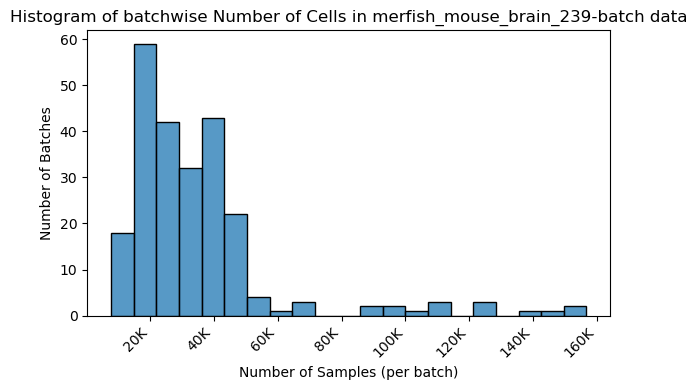

In [171]:
save_plot = True
histogram_num_cells(df,
                    save_plot=save_plot,
                    plots_directory=plots_directory,
                    dataset_name=dataset_name)

## Histogram of Cell and Niche Type Counts within a user-defined set of batches

In [182]:
def plot_cell_niche_type_histogram(batch_ids, 
                                   df,
                                   save_plot=True,
                                   plots_directory=plots_directory,
                                   dataset_name=dataset_name):
    
    fig,ax = plt.subplots(1,2,figsize=(18,6))
    cell_columns = [col for col in df.columns if col.startswith('cell_')]
    cell_types = [col.split('_')[1] for col in cell_columns]
    cell_counts = df[cell_columns].astype(np.int64).values.sum(axis=0)
    assert np.sum(cell_counts) == df['n_cells'].sum(axis=0)
    ax[0].bar(cell_types, cell_counts, label='Cell Type')
    ax[0].set_xlabel('Cell Types')
    ax[0].set_ylabel('Number of Samples')
    ax[0].set_title('Histogram of Cell Types')
    cell_type_labels = [cell_type.capitalize() for cell_type in cell_types]
    tick_positions = range(len(cell_type_labels))
    ax[0].set_xticks(tick_positions)
    ax[0].set_xticklabels(cell_type_labels, rotation=45, ha='right')

    niche_columns = [col for col in df.columns if col.startswith('niche_')]
    niche_types = [col.split('_')[1] for col in niche_columns]
    niche_counts = df[niche_columns].astype(np.int64).values.sum(axis=0)
    assert np.sum(niche_counts) == df['n_cells'].sum(axis=0)
    ax[1].bar(niche_types, niche_counts, label='Niche Type')
    ax[1].set_xlabel('Niche Types')
    ax[1].set_ylabel('Number of Samples')
    ax[1].set_title('Histogram of Niche Types')
    niche_type_labels = [niche_type.capitalize() for niche_type in niche_types]
    tick_positions = range(len(niche_type_labels))
    ax[1].set_xticks(tick_positions)
    ax[1].set_xticklabels(niche_type_labels, rotation=45, ha='right')
    
    total_n_cells = df['n_cells'].sum(axis=0)
    if isinstance(batch_ids,int):
        plt.suptitle(f'Batch {batch_ids} containing {total_n_cells} Samples for {dataset_name} data')
        output_fname = plots_directory / f"{dataset_name}_batch_{batch_ids}_cell_niche_type_histogram.png"
    elif isinstance(batch_ids,list):
        plt.suptitle(f'Batches {batch_ids} containing {total_n_cells} Samples for {dataset_name} data')
        batch_ids_str = '_'.join([str(batch_id) for batch_id in batch_ids])
        output_fname = plots_directory / f"{dataset_name}_batches_{batch_ids_str}_cell_niche_type_histogram.png"
    
    if save_plot:
        fig.tight_layout()
        plt.savefig(output_fname, dpi=300)
    else:
        plt.show()

In [185]:
final_choice_batch_ids_three_hundredk_data = [[217, 218]]

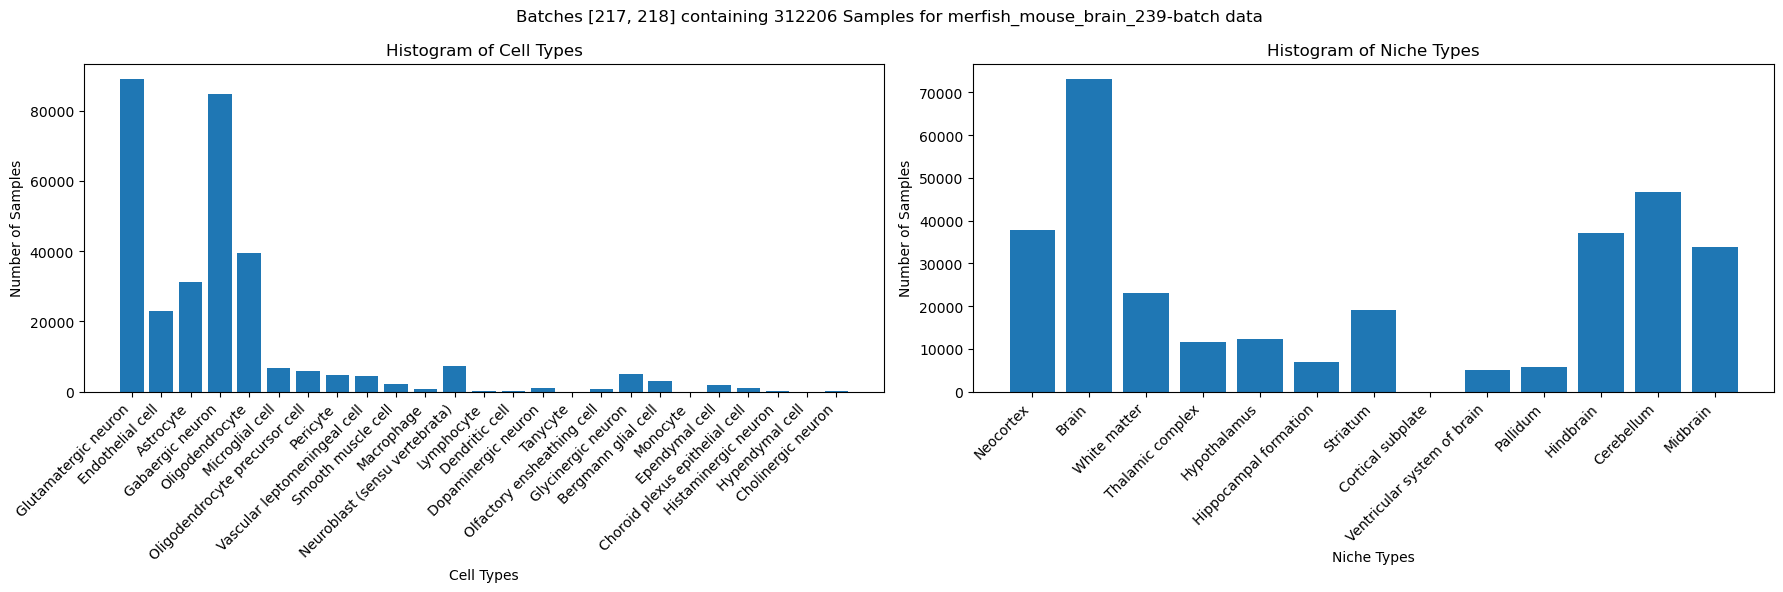

In [186]:
save_plot = True
for batch_id_list in final_choice_batch_ids_three_hundredk_data:
    batches_df = df[df['batch_id'].isin(batch_id_list)]
    batches_df = batches_df.drop(columns=['batch_id', 'n_genes'])
    batches_df = batches_df.sum(axis=0).to_frame().astype(np.int64).T
    
    plot_cell_niche_type_histogram(batch_id_list, 
                                   batches_df,
                                   save_plot=save_plot,
                                   plots_directory=plots_directory,
                                   dataset_name=dataset_name)

In [183]:
final_choice_batch_id_hundredk_data = 214
print(hundredk_batch_ids)

[224, 214, 223, 222, 221, 219, 215, 220, 216, 217, 218]


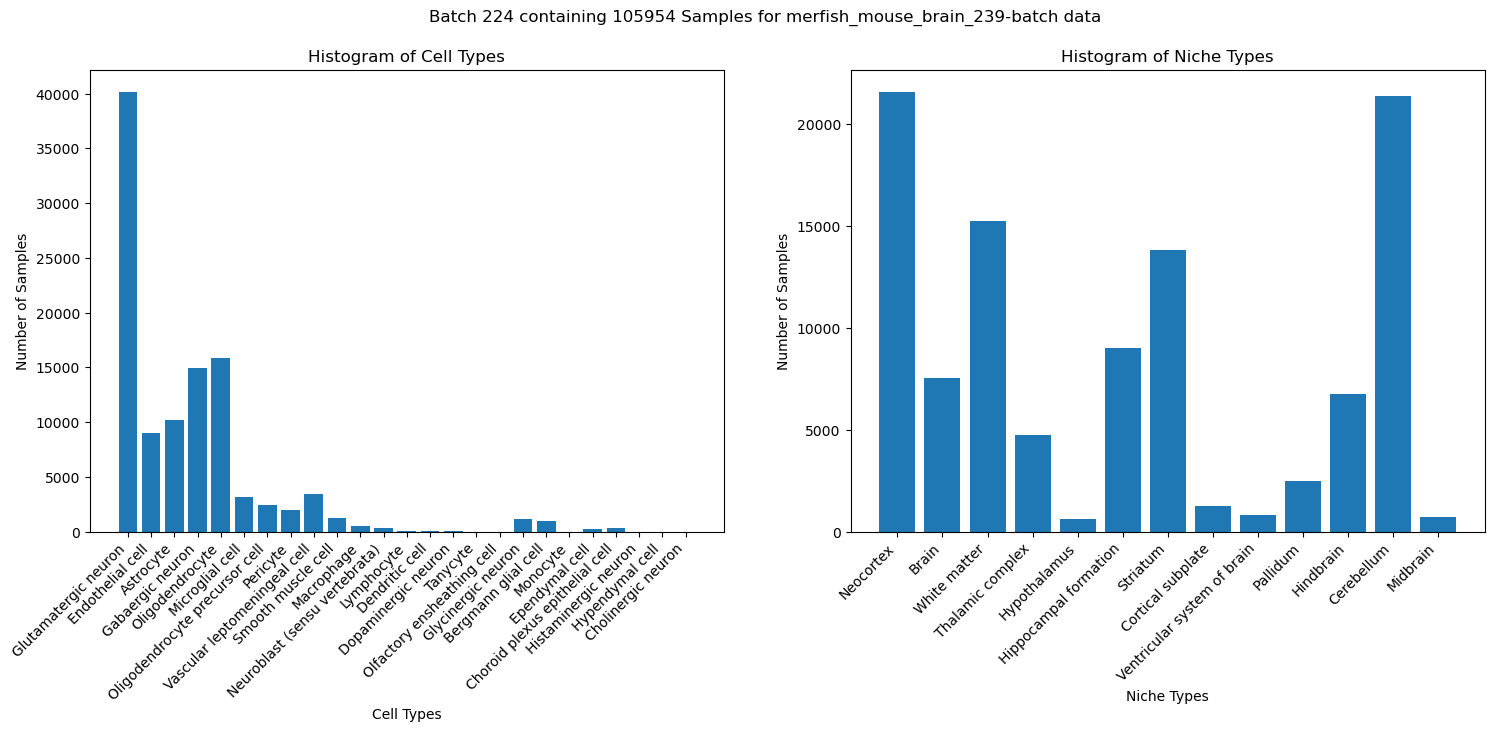

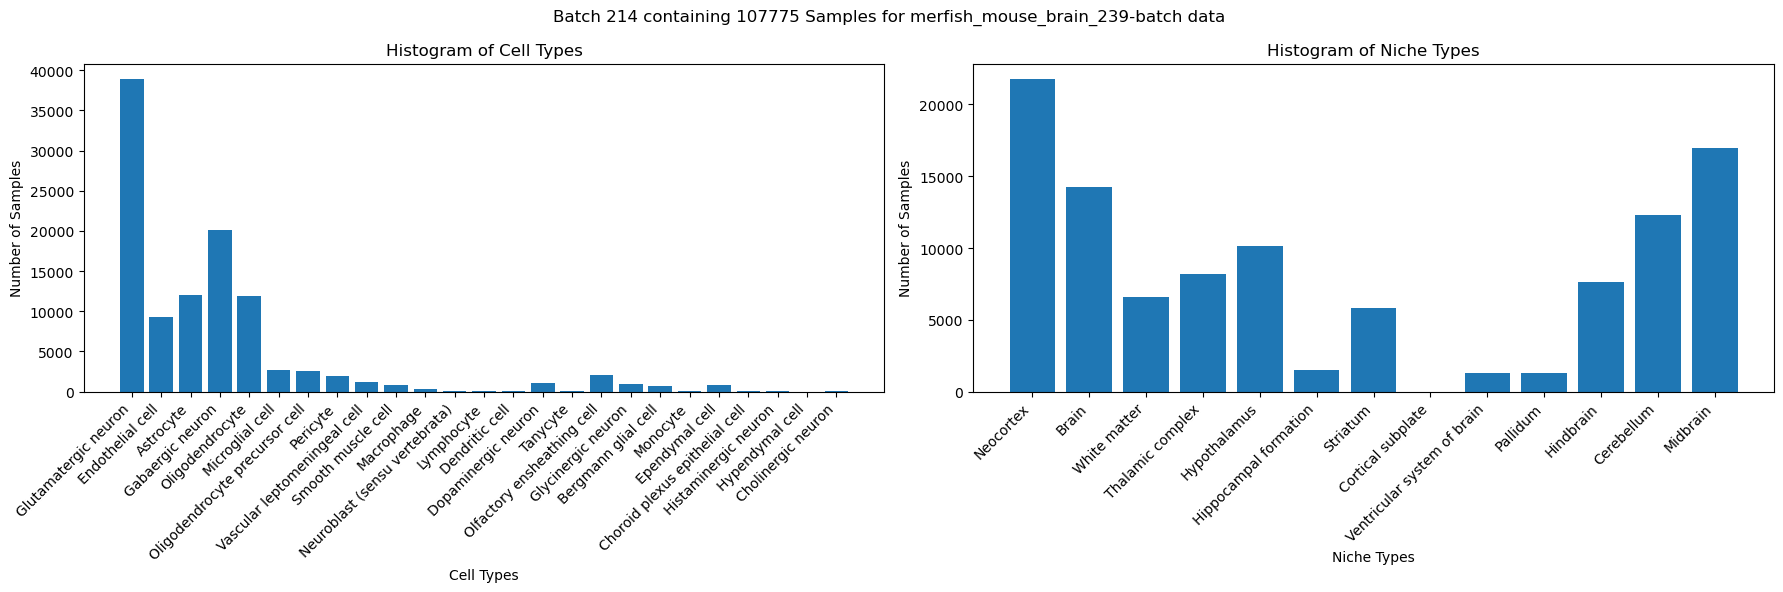

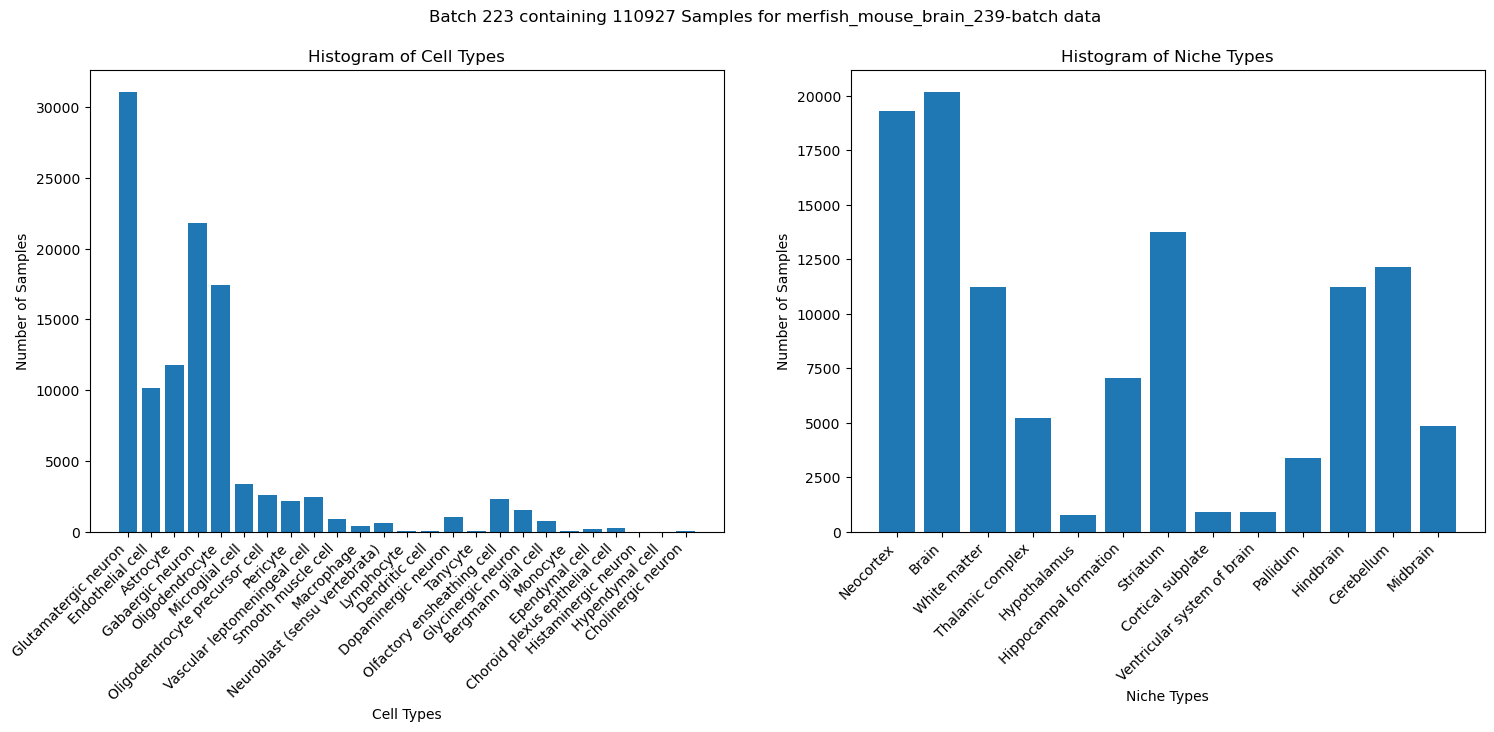

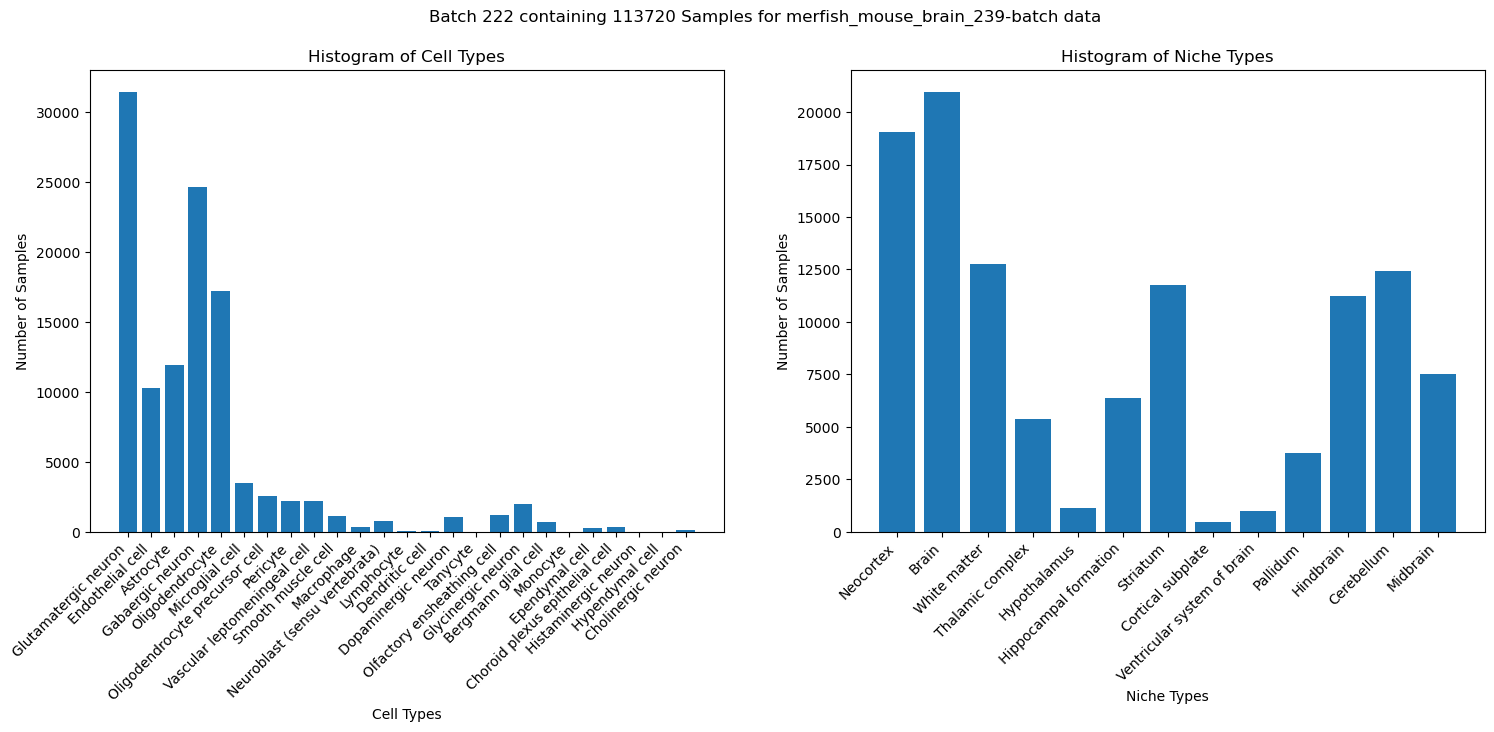

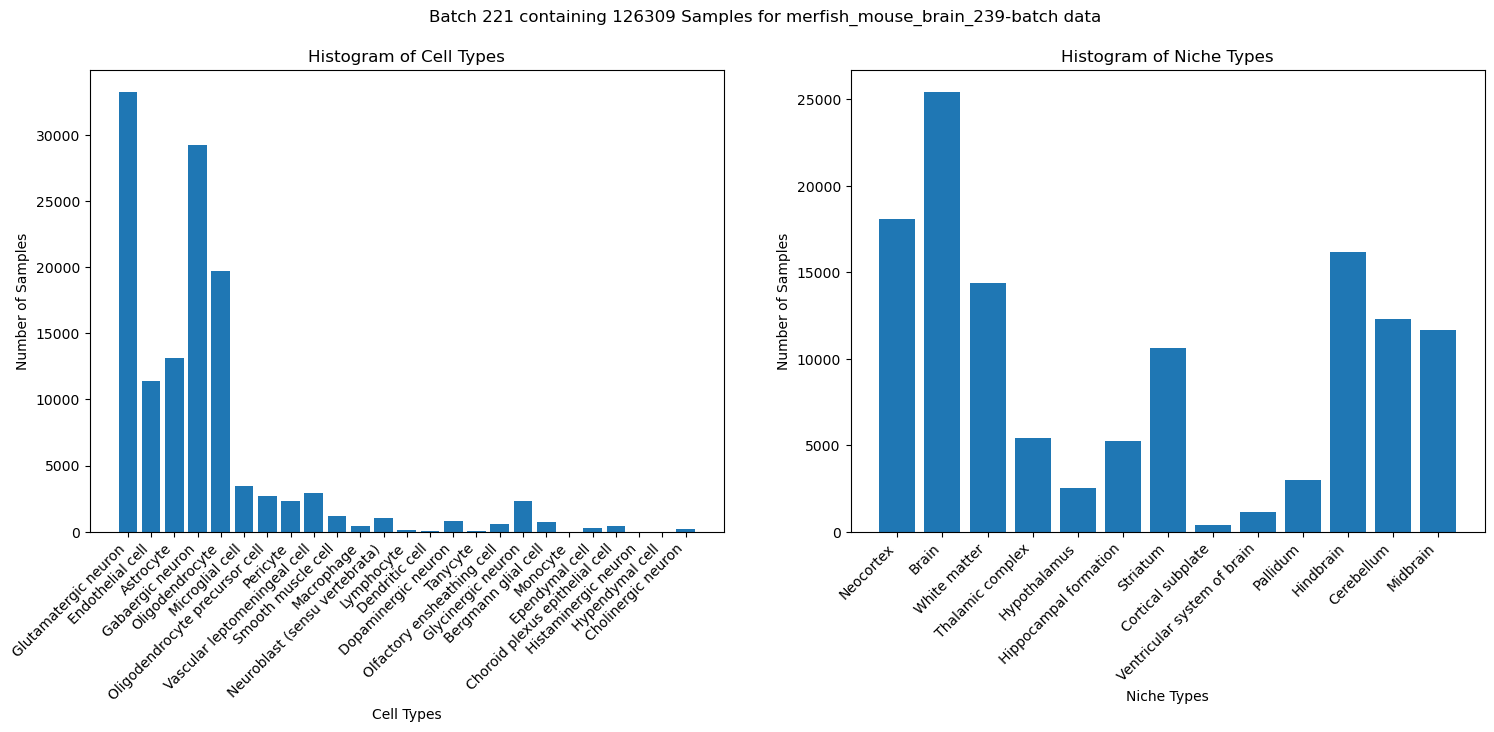

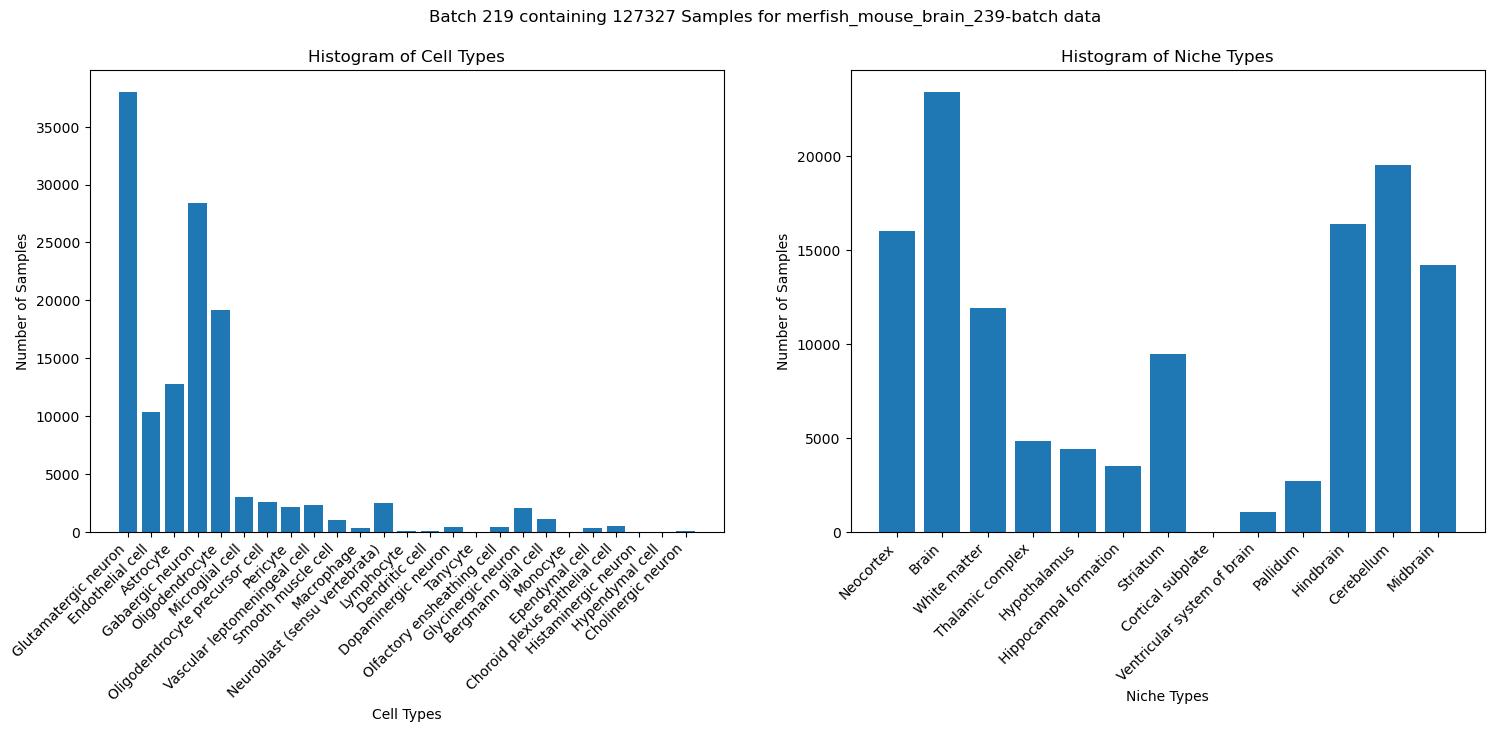

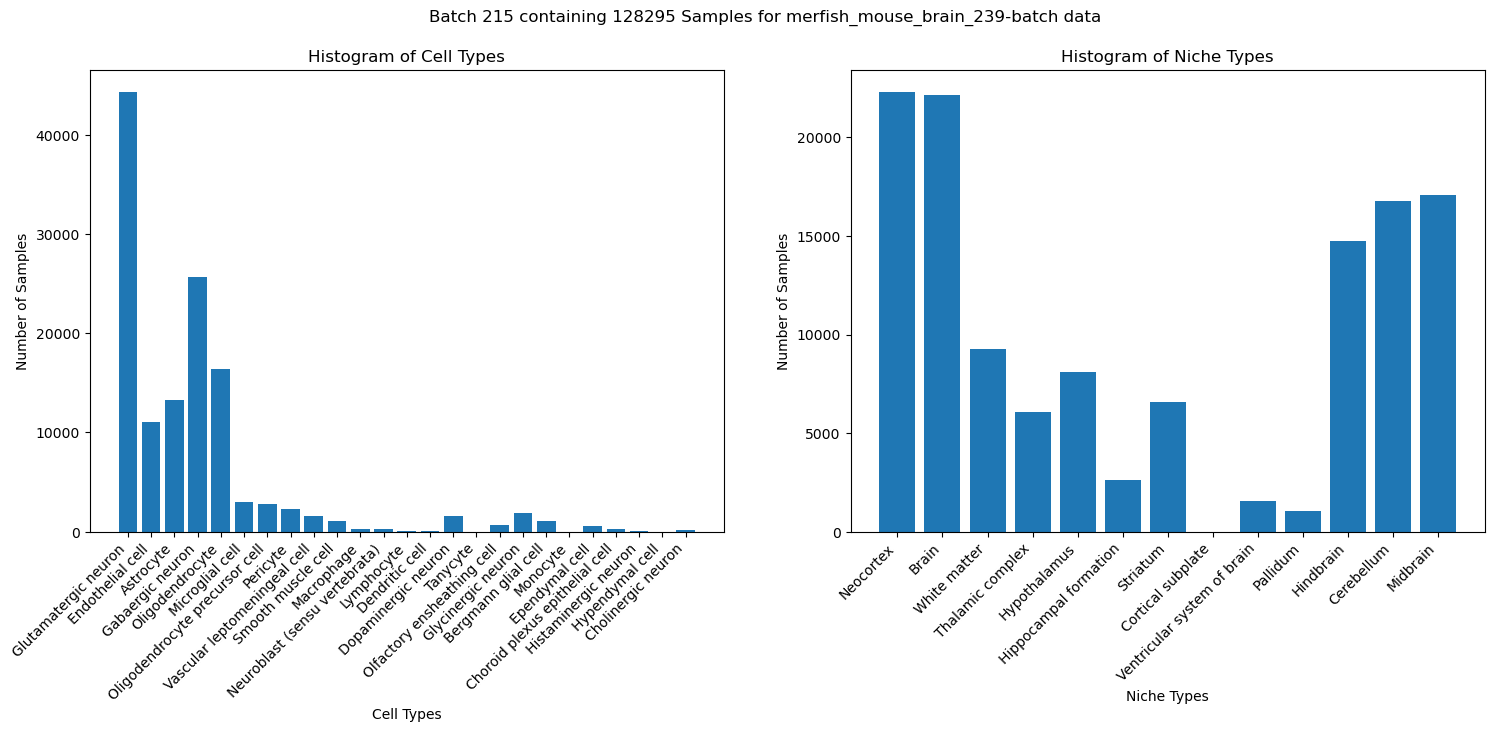

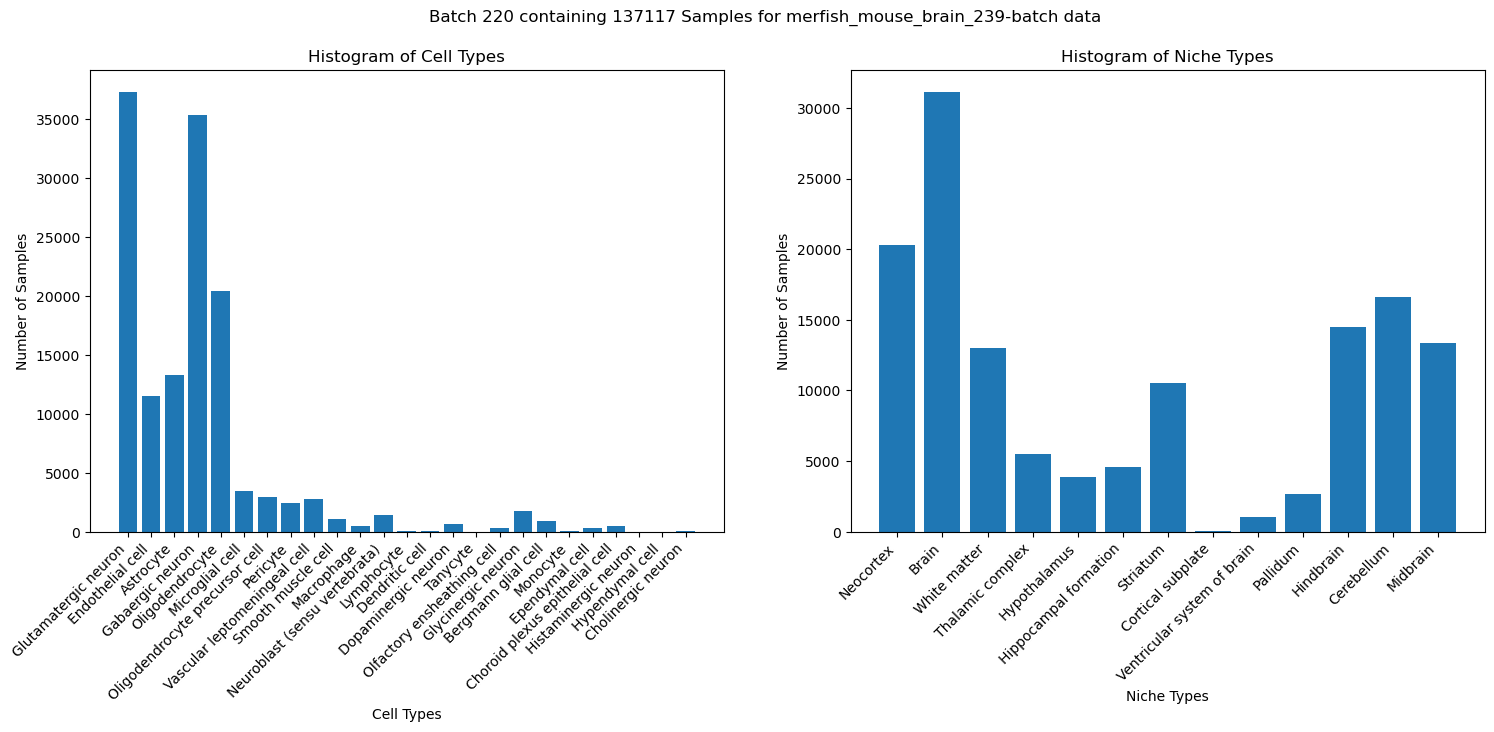

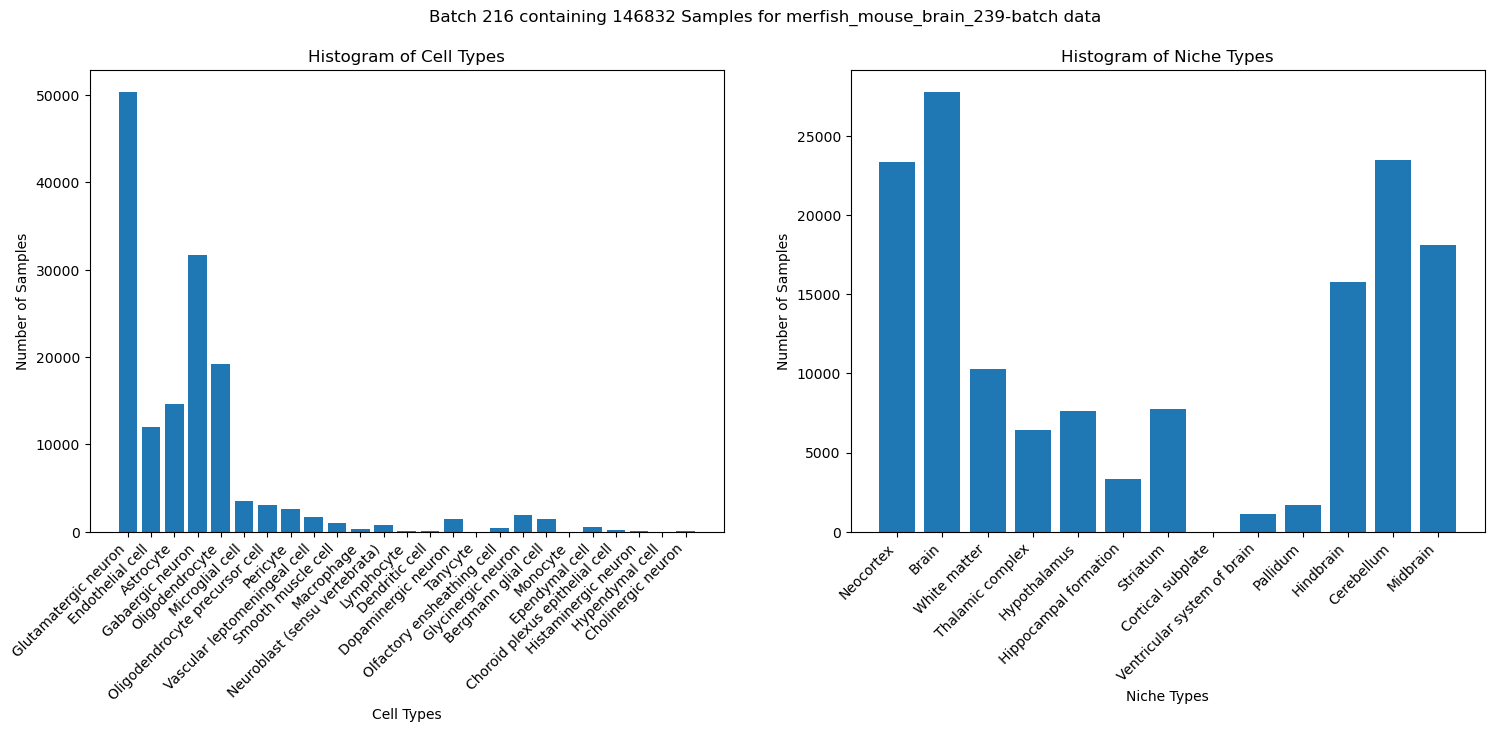

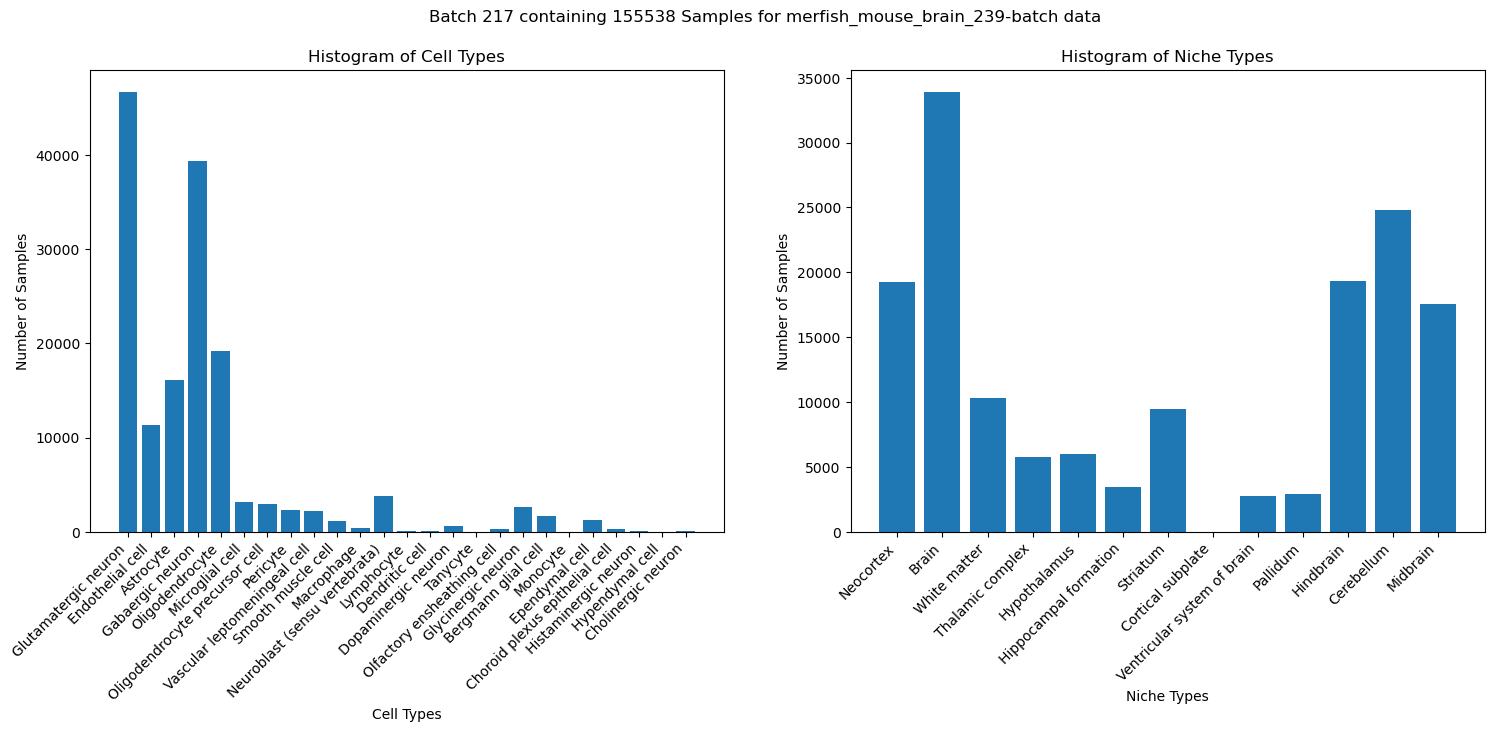

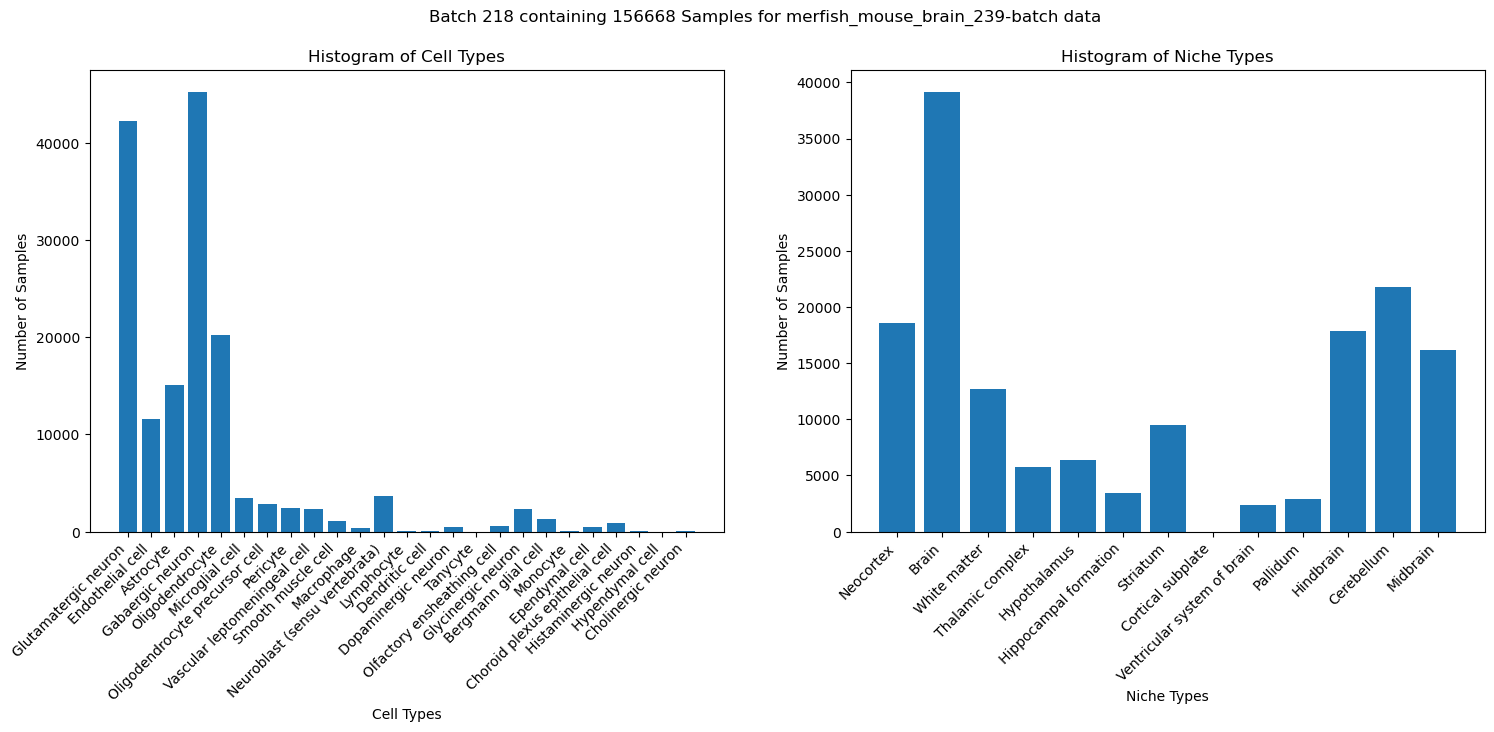

In [184]:
for batch_id in hundredk_batch_ids:
    if batch_id == final_choice_batch_id_hundredk_data:
        save_plot = True
    else:
        save_plot = False
        
    batch_df = hundredk_subset_df[hundredk_subset_df['batch_id'] == batch_id]
    
    plot_cell_niche_type_histogram(batch_id, 
                                   batch_df,
                                   save_plot=save_plot,
                                   plots_directory=plots_directory,
                                   dataset_name=dataset_name)